In [22]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, AutoMinorLocator
from joblib import Parallel, delayed

In [23]:
# ── Physics constants (same as Acoustic_Expander_22.ipynb) ──────────────────
gamma = 1.41
R     = 287
cp    = 1050
cv    = 744

P_in  = 6e5
P_out = 5.45e5
T_in  = 300.0
T0    = T_in

# Fixed initial pressure for the heatmap scan
# (midpoint of the range used in trajectory scans)
P0_fixed = 5.7e5

A_neck  = 2.85e-4   # m²
L_neck  = 0.15      # m
m_gas   = 0.0015    # kg
V0_cv   = 5.91e-5   # m³
V0_pass = 3.93e-4   # m³
b_gas   = 0.01

In [24]:
def reed_flow(dP, m_max, dP_max):
    """Mass flow through reed valve (positive = flow from high to low pressure)."""
    u = dP / dP_max
    if dP > 0 and dP < dP_max:
        return m_max * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return -m_max * (1 - u) * np.sqrt(abs(u))
    else:
        return 0.0

In [25]:
def _simulate_task(
    m_max_val, zeta_val,
    _P_in, _P_out, _P0_fixed,
    _R, _cp, _cv, _T_in, _T0, _gamma,
    _A_neck, _L_neck, _V0_cv, _V0_pass, _m_gas, _b_gas,
    t_span=(0.0, 5.0), n_eval=25_000, tail_window=2.0,
):
    """
    Fully self-contained worker for joblib loky.
    Returns half peak-to-peak amplitude of P_cv over the last
    `tail_window` seconds, or NaN on failure.
    """
    import numpy as np
    from scipy.integrate import solve_ivp

    # ── Local reed_flow (no globals) ──────────────────────────────────────
    def _reed(dP, m_max, dP_max):
        u = dP / dP_max
        if dP > 0 and dP < dP_max:
            return m_max * (1 - u) * np.sqrt(u)
        elif dP <= 0:
            return -m_max * (1 - u) * np.sqrt(abs(u))
        else:
            return 0.0

    # ── Derived reed parameters from zeta ────────────────────────────────
    dP_reed = _P_in - _P_out
    dP_max  = dP_reed / (2.0 * zeta_val)

    # ── ODE ──────────────────────────────────────────────────────────────
    def ode(t, y):
        x, v, M_cv, E_cv = y
        V_cv  = _V0_cv  + x * _A_neck
        V_pass = _V0_pass - x * _A_neck
        T_cv  = E_cv / (_cv * M_cv) if M_cv > 1e-12 else _T0
        P_cv  = M_cv * _R * T_cv / V_cv
        P_pass = _P0_fixed * (_V0_pass / V_pass) ** _gamma if V_pass > 1e-12 else _P0_fixed

        m_in  = _reed(_P_in  - P_cv, m_max_val, dP_max)
        m_out = _reed(P_cv - _P_out, m_max_val, dP_max)

        dV = _A_neck * v
        dM = m_in - m_out
        dE = -P_cv * dV + m_in * _cp * _T_in - m_out * _cp * T_cv
        dv = (P_cv - P_pass) * _A_neck / _m_gas - (_b_gas / _m_gas) * v
        return [v, dv, dM, dE]

    # ── Initial conditions ────────────────────────────────────────────────
    x0 = 0.01 * _L_neck          # small perturbation (matches Acoustic_Expander_22.ipynb)
    M0 = _P0_fixed * _V0_cv / (_R * _T0)
    E0 = _cv * M0 * _T0
    y0 = [x0, 0.0, M0, E0]

    try:
        t_eval = np.linspace(t_span[0], t_span[1], n_eval)
        sol = solve_ivp(
            ode, t_span, y0, t_eval=t_eval,
            method='RK45', rtol=1e-6, atol=1e-8,
        )
        t = sol.t
        x   = sol.y[0]
        M_c = sol.y[2]
        E_c = sol.y[3]

        V_cv = _V0_cv + x * _A_neck
        T_cv = E_c / (_cv * M_c)
        P_cv = M_c * _R * T_cv / V_cv

        # Amplitude over last `tail_window` seconds
        mask = t >= (t[-1] - tail_window)
        seg  = P_cv[mask]
        if seg.size < 3:
            return np.nan
        return 0.5 * (np.nanmax(seg) - np.nanmin(seg))
    except Exception:
        return np.nan

In [27]:
# ── Scan configuration ───────────────────────────────────────────────────────
m_max_range = np.linspace(0.0005, 0.002, 15)   # kg/s
zeta_range  = np.linspace(0.6,    2.0,   15)   # dimensionless

# Simulation settings
t_span      = (0.0, 6)
n_eval      = 20_000      # 5 kHz sampling → ~37 pts/cycle at 135 Hz
tail_window = 1.0         # use last 2 s for amplitude measurement

phys = dict(
    _P_in=P_in, _P_out=P_out, _P0_fixed=P0_fixed,
    _R=R, _cp=cp, _cv=cv, _T_in=T_in, _T0=T0, _gamma=gamma,
    _A_neck=A_neck, _L_neck=L_neck,
    _V0_cv=V0_cv, _V0_pass=V0_pass,
    _m_gas=m_gas, _b_gas=b_gas,
)

print(f"Grid: {len(m_max_range)} × {len(zeta_range)} = {len(m_max_range)*len(zeta_range)} simulations")
print(f"P0_fixed = {P0_fixed/1e5:.4f} bar")

Grid: 15 × 15 = 225 simulations
P0_fixed = 5.7000 bar


In [28]:
# ── Parallel computation ─────────────────────────────────────────────────────
# Suppress thread oversubscription in child processes
for _k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_k, "1")

tasks = [(m, z) for m in m_max_range for z in zeta_range]

results_flat = Parallel(n_jobs=-1, backend="loky", verbose=5)(
    delayed(_simulate_task)(
        m, z,
        **phys,
        t_span=t_span, n_eval=n_eval, tail_window=tail_window,
    )
    for m, z in tasks
)

# ── Assemble heat matrix  [rows = zeta, cols = m_max]  ──────────────────────
# shape: (n_zeta, n_mmax)  so imshow with origin='lower' gives
#   x-axis = m_max, y-axis = zeta
heat = np.full((len(zeta_range), len(m_max_range)), np.nan)
for k, (m, z) in enumerate(tasks):
    i_m = np.searchsorted(m_max_range, m)
    i_z = np.searchsorted(zeta_range,  z)
    heat[i_z, i_m] = results_flat[k]

print(f"NaN fraction: {np.isnan(heat).mean():.1%}")
print(f"Amplitude range: {np.nanmin(heat):.1f} – {np.nanmax(heat):.1f} Pa")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    6.2s
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:   15.8s


NaN fraction: 0.0%
Amplitude range: 0.0 – 30780.4 Pa


[Parallel(n_jobs=-1)]: Done 225 out of 225 | elapsed:   25.7s finished


In [29]:
def plot_heatmap_mmax_zeta(
    heat, m_max_vals, zeta_vals,
    save_path="heatmap_mmax_zeta.pdf",
    title=None, cmap="viridis", dpi_png=600,
):
    """
    Publication-quality heatmap: x = m_max (kg/s), y = zeta.
    heat shape: (len(zeta_vals), len(m_max_vals))
    """
    with mpl.rc_context({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 16,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "axes.linewidth": 1.2,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    }):
        fig, ax = plt.subplots(figsize=(6.8, 4.8))

        finite = np.isfinite(heat)
        vmin = np.nanpercentile(heat[finite], 1)  if np.any(finite) else None
        vmax = np.nanpercentile(heat[finite], 99) if np.any(finite) else None
        if vmin is not None and np.isclose(vmin, vmax):
            vmin, vmax = None, None

        im = ax.imshow(
            heat,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            extent=[
                m_max_vals.min() * 1e3, m_max_vals.max() * 1e3,   # g/s for readability
                zeta_vals.min(),        zeta_vals.max(),
            ],
            cmap=cmap,
            vmin=vmin, vmax=vmax,
        )

        ax.set_xlabel(r"$\dot{m}_{\mathrm{max}}$ (g/s)")
        ax.set_ylabel(r"$\zeta$")
        ax.set_title(title or r"Oscillation amplitude of $P_{\mathrm{cv}}$ (half peak-to-peak)")

        ax.xaxis.set_major_locator(MaxNLocator(6))
        ax.yaxis.set_major_locator(MaxNLocator(6))
        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.tick_params(which="both", top=False, right=False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        cbar = fig.colorbar(im, ax=ax, pad=0.02)
        cbar.set_label(r"Amplitude (Pa)")
        cbar.outline.set_linewidth(1.2)
        cbar.ax.tick_params(width=1.2, direction="in")
        cbar.formatter = mpl.ticker.ScalarFormatter(useMathText=True)
        cbar.formatter.set_powerlimits((-2, 2))
        cbar.update_ticks()

        if save_path:
            root, ext = os.path.splitext(save_path)
            fig.savefig(save_path)
            fig.savefig(root + ".png", dpi=dpi_png)

        plt.show()
        return fig, ax

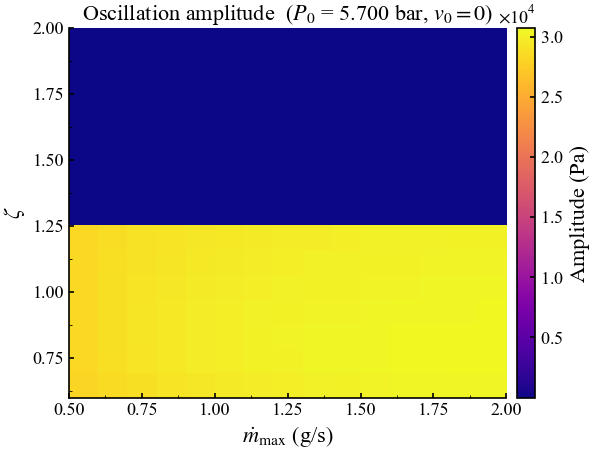

(<Figure size 680x480 with 2 Axes>,
 <Axes: title={'center': 'Oscillation amplitude  ($P_0$ = 5.700 bar, $v_0=0$)'}, xlabel='$\\dot{m}_{\\mathrm{max}}$ (g/s)', ylabel='$\\zeta$'>)

In [30]:
plot_heatmap_mmax_zeta(
    heat, m_max_range, zeta_range,
    save_path="heatmap_mmax_zeta.pdf",
    cmap="plasma",
    title=fr"Oscillation amplitude  ($P_0$ = {P0_fixed/1e5:.3f} bar, $v_0=0$)",
)


── P0_fixed = 5.6000 bar ──


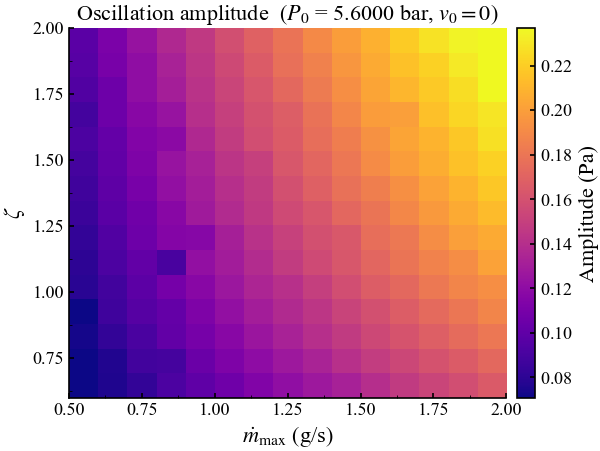

  NaN fraction: 0.0%  |  Amplitude range: 0.1 – 0.2 Pa

── P0_fixed = 5.6222 bar ──


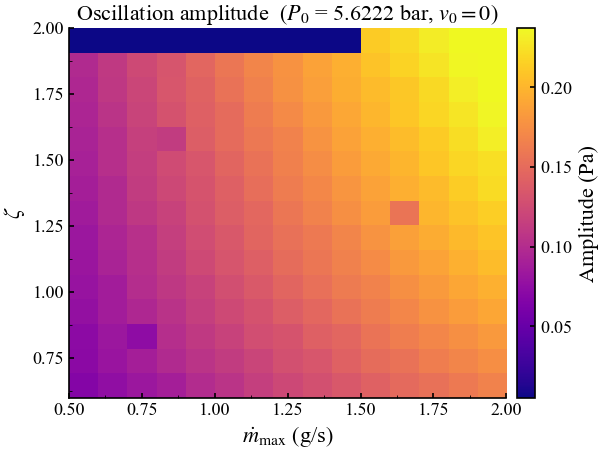

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 0.2 Pa

── P0_fixed = 5.6444 bar ──


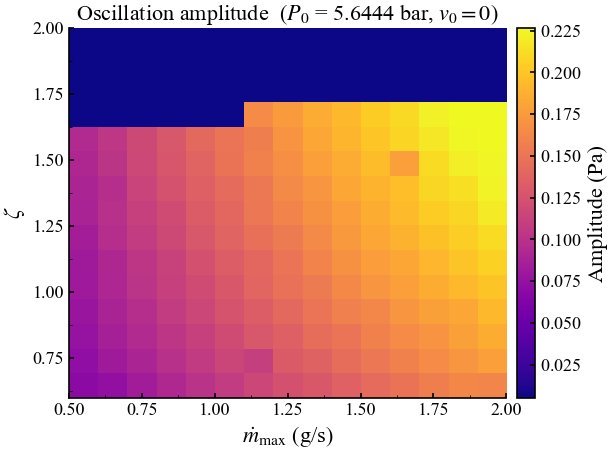

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 0.2 Pa

── P0_fixed = 5.6667 bar ──


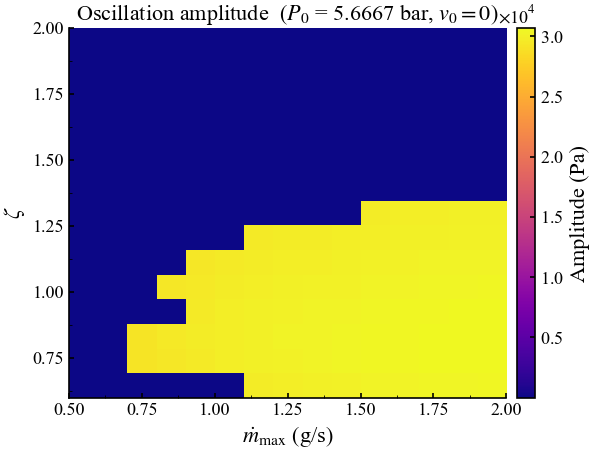

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 30760.0 Pa

── P0_fixed = 5.6889 bar ──


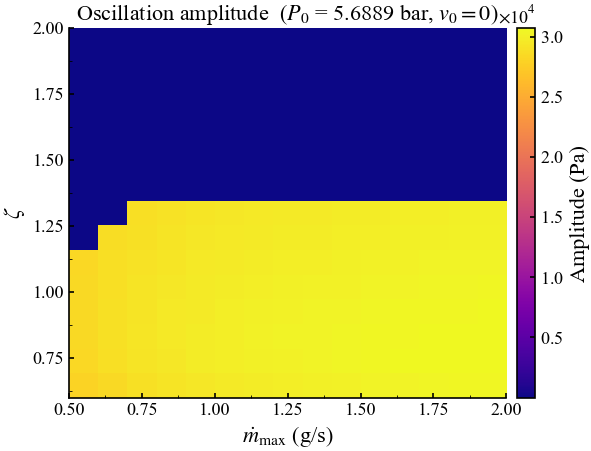

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 30779.6 Pa

── P0_fixed = 5.7111 bar ──


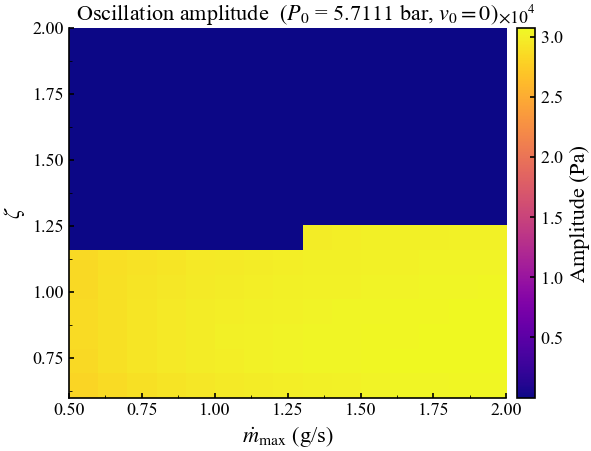

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 30794.4 Pa

── P0_fixed = 5.7333 bar ──


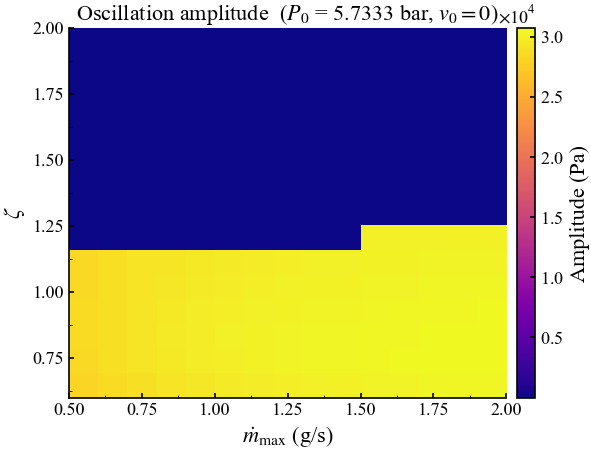

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 30826.8 Pa

── P0_fixed = 5.7556 bar ──


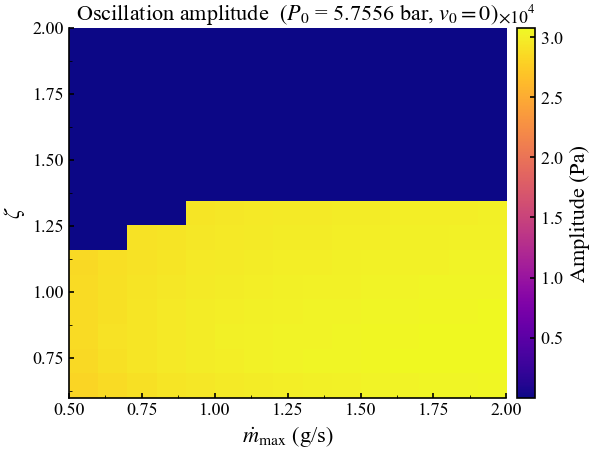

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 30845.7 Pa

── P0_fixed = 5.7778 bar ──


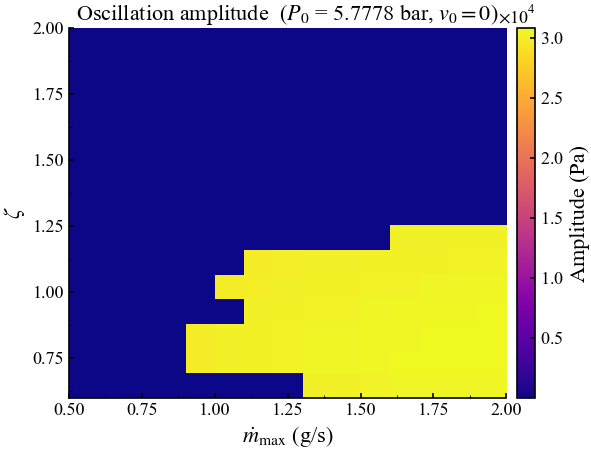

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 30852.6 Pa

── P0_fixed = 5.8000 bar ──


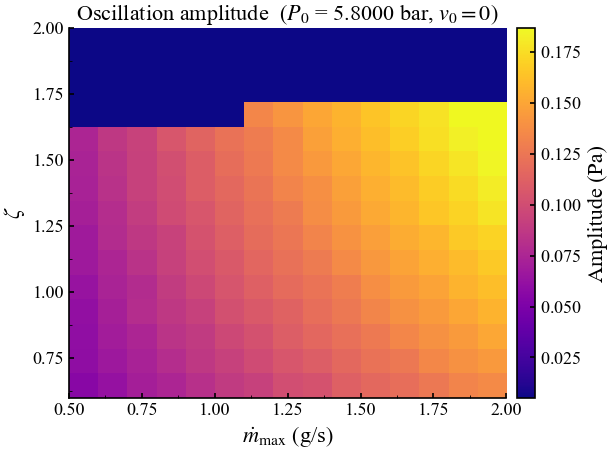

  NaN fraction: 0.0%  |  Amplitude range: 0.0 – 0.2 Pa


In [31]:
# ── Multi-P0 scan: 10 values from 5.6 bar to 5.8 bar ────────────────────────
P0_values = np.linspace(5.6e5, 5.8e5, 10)

for P0_fixed_i in P0_values:
    print(f"\n── P0_fixed = {P0_fixed_i/1e5:.4f} bar ──")

    phys_i = dict(
        _P_in=P_in, _P_out=P_out, _P0_fixed=P0_fixed_i,
        _R=R, _cp=cp, _cv=cv, _T_in=T_in, _T0=T0, _gamma=gamma,
        _A_neck=A_neck, _L_neck=L_neck,
        _V0_cv=V0_cv, _V0_pass=V0_pass,
        _m_gas=m_gas, _b_gas=b_gas,
    )

    results_flat_i = Parallel(n_jobs=-1, backend="loky", verbose=0)(
        delayed(_simulate_task)(
            m, z,
            **phys_i,
            t_span=t_span, n_eval=n_eval, tail_window=tail_window,
        )
        for m, z in tasks
    )

    heat_i = np.full((len(zeta_range), len(m_max_range)), np.nan)
    for k, (m, z) in enumerate(tasks):
        i_m = np.searchsorted(m_max_range, m)
        i_z = np.searchsorted(zeta_range,  z)
        heat_i[i_z, i_m] = results_flat_i[k]

    tag = f"P0={P0_fixed_i/1e5:.4f}bar"
    plot_heatmap_mmax_zeta(
        heat_i, m_max_range, zeta_range,
        save_path=f"heatmap_mmax_zeta_{tag}.pdf",
        cmap="plasma",
        title=fr"Oscillation amplitude  ($P_0$ = {P0_fixed_i/1e5:.4f} bar, $v_0=0$)",
    )
    print(f"  NaN fraction: {np.isnan(heat_i).mean():.1%}  |  "
          f"Amplitude range: {np.nanmin(heat_i):.1f} – {np.nanmax(heat_i):.1f} Pa")